# Deskripsi library yang digunakan

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [1]:
!pip install scikit-learn

   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   --- ------------------------------------ 0.8/8.4 MB 4.1 MB/s eta 0:00:02
   -------- ------------------------------- 1.8/8.4 MB 4.7 MB/s eta 0:00:02
   ------------ --------------------------- 2.6/8.4 MB 4.8 MB/s eta 0:00:02
   ------------- -------------------------- 2.9/8.4 MB 3.8 MB/s eta 0:00:02
   ------------------ --------------------- 3.9/8.4 MB 4.0 MB/s eta 0:00:02
   ----------------------- ---------------- 5.0/8.4 MB 4.1 MB/s eta 0:00:01
   ---------------------------- ----------- 6.0/8.4 MB 4.2 MB/s eta 0:00:01
   --------------------------------- ------ 7.1/8.4 MB 4.4 MB/s eta 0:00:01
   -------------------------------------- - 8.1/8.4 MB 4.5 MB/s eta 0:00:01
   ---------------------------------------- 8.4/8.4 MB 4.3 MB/s  0:00:01
   ---------------------------------------- 0.0/37.4 MB ? eta -:--:--
   ---------------------------------------- 0.3/37.4 MB ? eta -:--:--
   - -----------------------------

# Memanggil Dataset

In [10]:
df = pd.read_csv('toyota.csv')

# Deskripsi Dataset

In [11]:
df.head ()

,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize
0,GT86,2016,16000,Manual,24089,Petrol,265,36.2,2.0
1,GT86,2017,15995,Manual,18615,Petrol,145,36.2,2.0
2,GT86,2015,13998,Manual,27469,Petrol,265,36.2,2.0
3,GT86,2017,18998,Manual,14736,Petrol,150,36.2,2.0
4,GT86,2017,17498,Manual,36284,Petrol,145,36.2,2.0


In [12]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6738 entries, 0 to 6737
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   model         6738 non-null   str    
 1   year          6738 non-null   int64  
 2   price         6738 non-null   int64  
 3   transmission  6738 non-null   str    
 4   mileage       6738 non-null   int64  
 5   fuelType      6738 non-null   str    
 6   tax           6738 non-null   int64  
 7   mpg           6738 non-null   float64
 8   engineSize    6738 non-null   float64
dtypes: float64(2), int64(4), str(3)
memory usage: 473.9 KB


<Axes: >

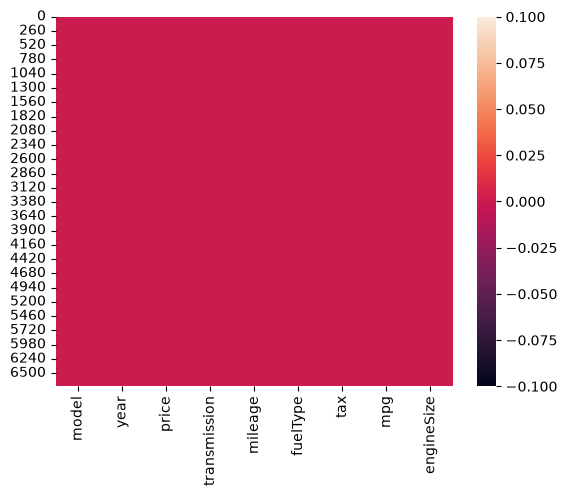

In [13]:
sns.heatmap(df.isnull())

In [14]:
df.describe() 

,year,price,mileage,tax,mpg,engineSize
count,6738.000000,6738.000000,6738.000000,6738.000000,6738.000000,6738.000000
mean,2016.748145,12522.391066,22857.413921,94.697240,63.042223,1.471297
std,2.204062,6345.017587,19125.464147,73.880776,15.836710,0.436159
min,1998.000000,850.000000,2.000000,0.000000,2.800000,0.000000
25%,2016.000000,8290.000000,9446.000000,0.000000,55.400000,1.000000
50%,2017.000000,10795.000000,18513.000000,135.000000,62.800000,1.500000
75%,2018.000000,14995.000000,31063.750000,145.000000,69.000000,1.800000
max,2020.000000,59995.000000,174419.000000,565.000000,235.000000,4.500000


# Visualisasi Data

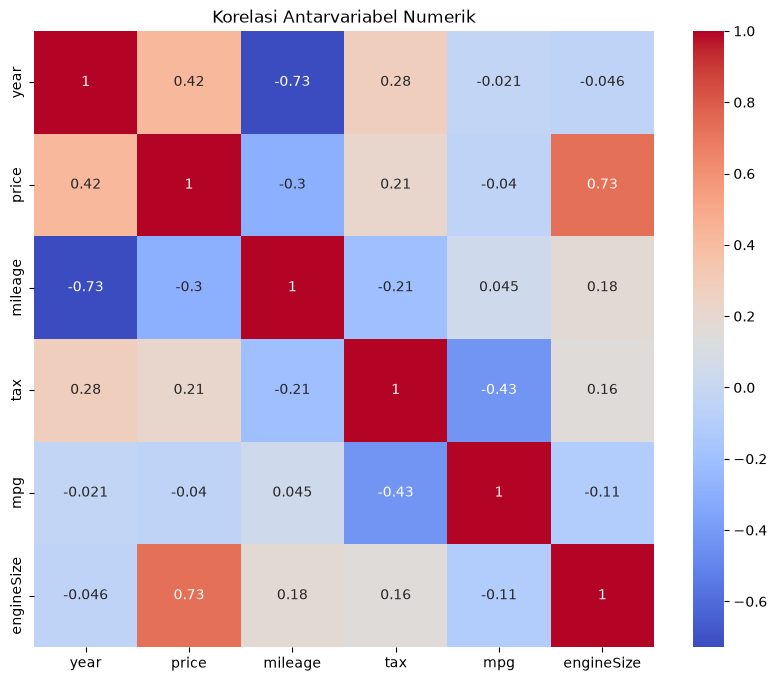

In [15]:
numeric_df = df.select_dtypes(include=["number"])

plt.figure(figsize=(10, 8))
sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm")
plt.title("Korelasi Antarvariabel Numerik")
plt.show()

# Jumlah mobil berdasarkan model

In [16]:
models = (
    df.groupby('model')
      .size()
      .reset_index(name='numberOfCars')
      .sort_values(by='numberOfCars', ascending=True)
)

models

,model,numberOfCars
16,Verso-S,3
14,Urban Cruiser,4
8,IQ,8
4,Camry,11
13,Supra,12
10,PROACE VERSO,15
9,Land Cruiser,51
6,GT86,73
7,Hilux,86
15,Verso,114


([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17],
 [Text(0, 0, ' Verso-S'),
  Text(1, 0, ' Urban Cruiser'),
  Text(2, 0, ' IQ'),
  Text(3, 0, ' Camry'),
  Text(4, 0, ' Supra'),
  Text(5, 0, ' PROACE VERSO'),
  Text(6, 0, ' Land Cruiser'),
  Text(7, 0, ' GT86'),
  Text(8, 0, ' Hilux'),
  Text(9, 0, ' Verso'),
  Text(10, 0, ' Avensis'),
  Text(11, 0, ' Prius'),
  Text(12, 0, ' Corolla'),
  Text(13, 0, ' RAV4'),
  Text(14, 0, ' C-HR'),
  Text(15, 0, ' Auris'),
  Text(16, 0, ' Aygo'),
  Text(17, 0, ' Yaris')])

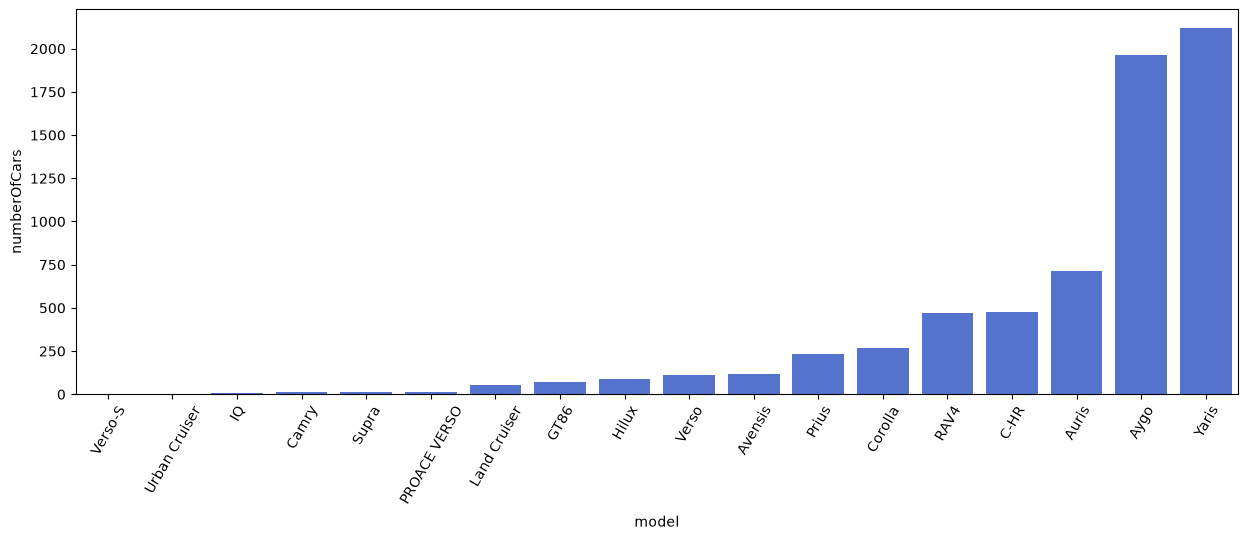

In [17]:
fig = plt.figure(figsize=(15,5))
sns.barplot(x=models['model'], y=models['numberOfCars'], color='royalblue')
plt.xticks(rotation=60)

# Ukuran Mesin

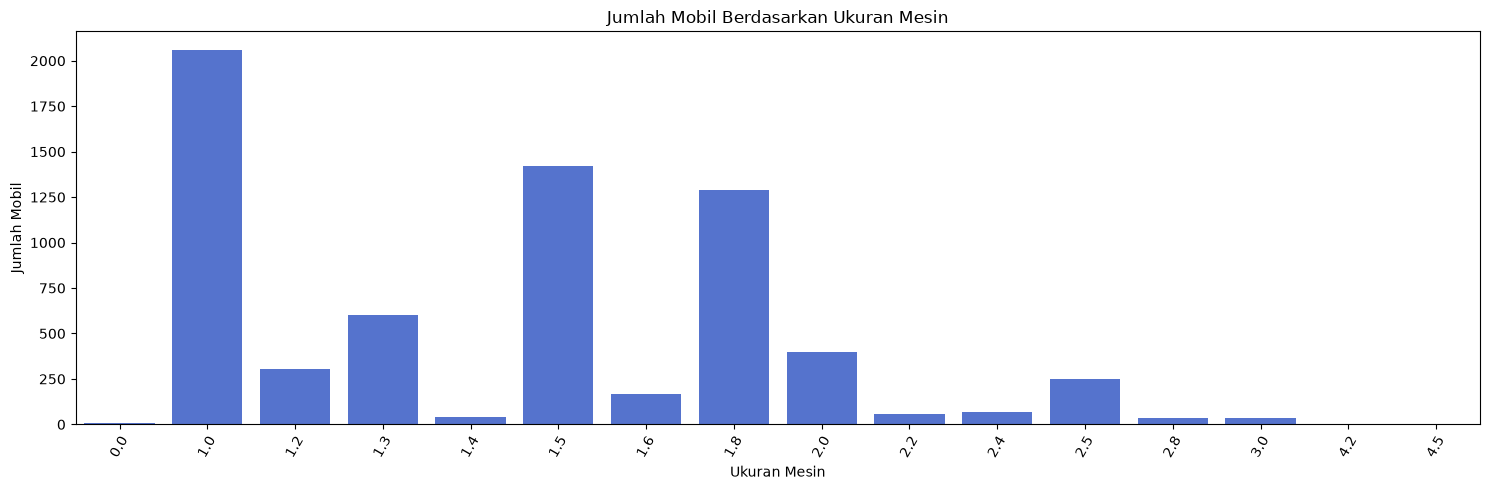

In [18]:
engine = (
    df.groupby("engineSize")
      .count()[["tax"]]
      .sort_values(by="tax", ascending=True)
      .reset_index()
)

engine = engine.rename(columns={"tax": "count"})

plt.figure(figsize=(15, 5))
sns.barplot(
    x=engine["engineSize"],
    y=engine["count"],
    color="royalblue"
)
plt.xticks(rotation=60)
plt.title("Jumlah Mobil Berdasarkan Ukuran Mesin")
plt.xlabel("Ukuran Mesin")
plt.ylabel("Jumlah Mobil")
plt.tight_layout()
plt.show()

# Distribusi mileage

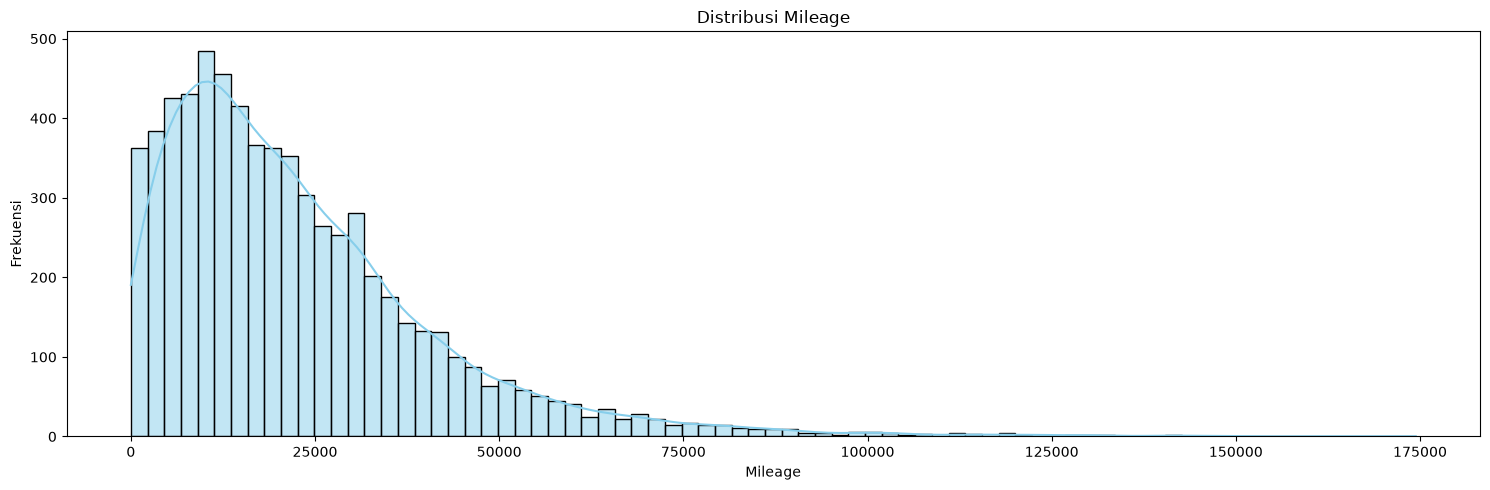

In [19]:
plt.figure(figsize=(15, 5))
sns.histplot(
    data=df,
    x="mileage",
    kde=True,
    color="skyblue"
)
plt.title("Distribusi Mileage")
plt.xlabel("Mileage")
plt.ylabel("Frekuensi")
plt.tight_layout()
plt.show()

# Distribusi harga mobil

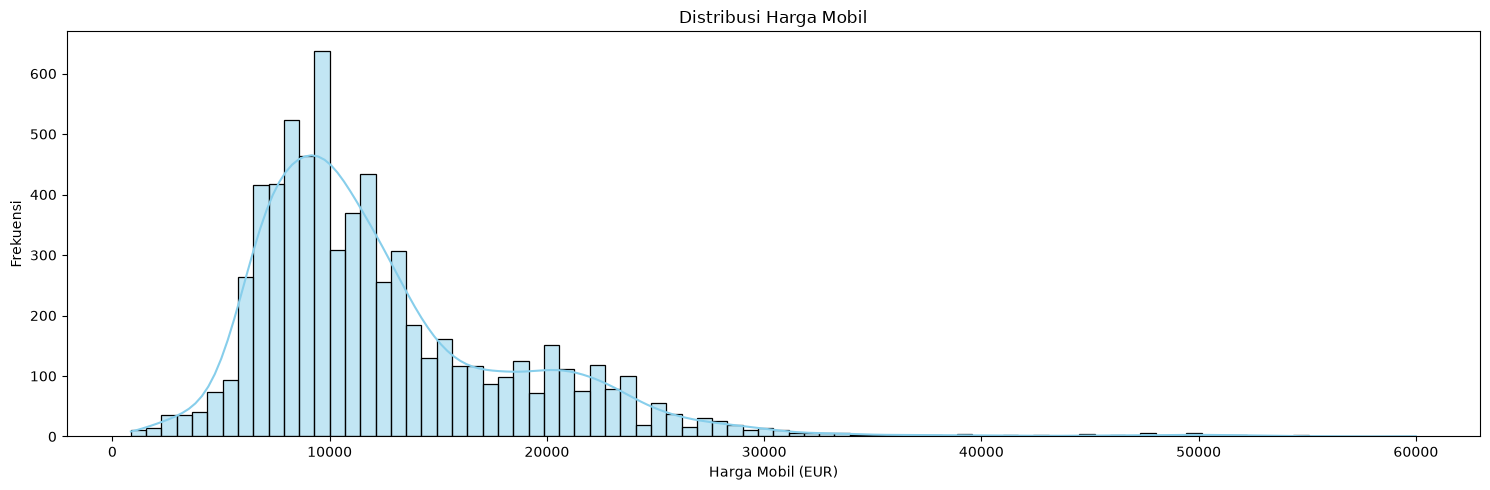

In [20]:
plt.figure(figsize=(15, 5))
sns.histplot(
    data=df,
    x="price",
    kde=True,
    color="skyblue"
)
plt.title("Distribusi Harga Mobil")
plt.xlabel("Harga Mobil (EUR)")
plt.ylabel("Frekuensi")
plt.tight_layout()
plt.show()

# Distribusi ukuran mesin

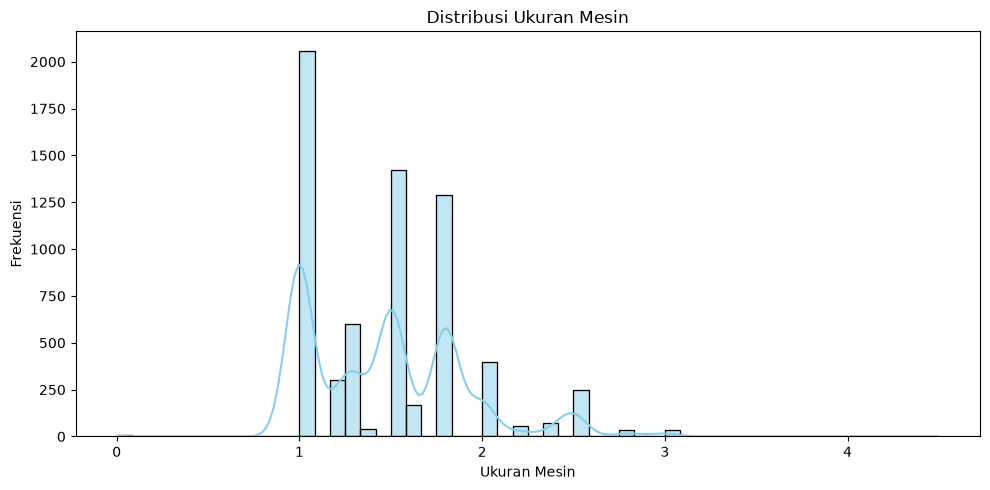

In [21]:
plt.figure(figsize=(10, 5))
sns.histplot(
    data=df,
    x="engineSize",
    kde=True,
    color="skyblue"
)
plt.title("Distribusi Ukuran Mesin")
plt.xlabel("Ukuran Mesin")
plt.ylabel("Frekuensi")
plt.tight_layout()
plt.show()

# Seleksi fitur

In [22]:
features = ['year','mileage','tax','mpg','engineSize']
x = df[features]
y = df['price']
x.shape, y.shape

((6738, 5), (6738,))

# Split data training dan data testing

In [23]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y,random_state=70)
y_test.shape

(1685,)

# MEMBUAT MODEL REGRESI LINIER

In [24]:
from sklearn.linear_model import LinearRegression
Ir = LinearRegression()
Ir.fit(x_train, y_train)
pred = Ir.predict(x_test)

In [25]:
score = Ir.score(x_test, y_test)
print('akurasi model regresi linier =', score)

akurasi model regresi linier = 0.7678983314475204


# Membuat inputan model regresi linier

In [28]:
#Year=2019, mileage=50000, tax=145, mpg=30, engineSize=2.2
input_data = np.array([[2019,5000,145,30.2,2]])

prediction = Ir.predict(input_data)
print('Estimasi harga mobil dalam EUR:', prediction)

Estimasi harga mobil dalam EUR: [21208.50538579]


c:\File Kuliah\SEMESTER 7\DATA MINING\Data Kaggle\Estimasi Harga Mobil\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


# Save model

In [29]:
import pickle

filename = 'estimasi_mobil.sav'
pickle.dump(Ir, open(filename, 'wb'))